# Baltimore 311 Resolution Time: Median Baseline

**Team Chingu:** Manikrishneshwar Sasidhar, Yeo Eun Yoon

The plan's first model is a median resolution-time baseline. It is fit on earlier requests, scored on later requests, and compared with MAE, RMSE, and R². This notebook is that model. The linear regression notebook is the next one, and the tree-model notebook is the one after that.

Two versions of the same rule:

1. **One median for every request.** This is the baseline named in the proposal.
2. **One median per request type.** Request type is known when a request is filed, and the types do not share a resolution time, so this is the median rule the later models have to beat.

Both are fit on 2024 only and scored once on 2025. The rows are the same ones those later notebooks use, so the two scores here are the first two rows of the comparison.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
RESULTS_DIR = ROOT / "results"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Same analysis set as the linear regression and the tree models.
SLA_MAX = 120
MIN_TYPE_N = 200

MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def metrics(days_true, log_true, days_pred):
    # MAE, RMSE, and R² in days. R2_log scores log(1 + the day prediction),
    # so it is the same prediction converted, not a separately fit log model.
    days_true = np.asarray(days_true, dtype=float)
    log_true = np.asarray(log_true, dtype=float)
    days_pred = np.asarray(days_pred, dtype=float)
    log_pred = np.log1p(days_pred)
    e_days = days_true - days_pred
    e_log = log_true - log_pred
    return {
        "MAE": np.mean(np.abs(e_days)),
        "RMSE": np.sqrt(np.mean(e_days ** 2)),
        "R2": 1 - (e_days ** 2).sum() / ((days_true - days_true.mean()) ** 2).sum(),
        "R2_log": 1 - (e_log ** 2).sum() / ((log_true - log_true.mean()) ** 2).sum(),
    }

## 1. The same rows as the later notebooks

Source: `data/processed/311_clean_2024_2025.parquet` from the cleaning notebook.

The baseline does not use the city's deadline. Requests are still limited to `sla_days` from 0 through 120, which is the set the linear regression is scored on. A request dropped there should not remain in this score.

In [2]:
df = pd.read_parquet(PROCESSED_DIR / "311_clean_2024_2025.parquet")
n_clean = len(df)
df = df[df["sla_days"].between(0, SLA_MAX)].copy()

is_2024 = df["source_year"] == 2024
type_counts = df.loc[is_2024, "SRType"].value_counts()
common_types = set(type_counts[type_counts >= MIN_TYPE_N].index)
df["request_type"] = np.where(df["SRType"].isin(common_types), df["SRType"].astype(str), "Other")

print(f"Cleaned file             {n_clean:>10,} rows")
print(f"Deadline 0-{SLA_MAX} days        {len(df):>10,} rows")
print(f"  2024 (train)           {int(is_2024.sum()):>10,}")
print(f"  2025 (test)            {int((~is_2024).sum()):>10,}")
print(f"Request types with their own median: {len(common_types)}")
print(f"Share in Other: 2024 {(df.loc[is_2024, 'request_type'] == 'Other').mean():.1%}   "
      f"2025 {(df.loc[~is_2024, 'request_type'] == 'Other').mean():.1%}")

assert len(df) == 923_522, len(df)
assert int(is_2024.sum()) == 489_223
assert len(common_types) == 138
print("\nMatches the linear regression notebook.")

Cleaned file                931,339 rows
Deadline 0-120 days           923,522 rows
  2024 (train)              489,223
  2025 (test)               434,299
Request types with their own median: 138
Share in Other: 2024 1.4%   2025 1.9%

Matches the linear regression notebook.


## 2. Train on 2024, test on 2025

A median has no settings to choose, so there is no validation slice. 2024 supplies the medians. 2025 is scored once.

In [3]:
train = df[df["source_year"] == 2024].copy()
test = df[df["source_year"] == 2025].copy()

print(f"Training rows: {len(train):,}")
print(f"Test rows:     {len(test):,}")
print(f"2024 median {train['resolution_days'].median():.2f} days    mean {train['resolution_days'].mean():.2f} days")
print(f"2025 median {test['resolution_days'].median():.2f} days    mean {test['resolution_days'].mean():.2f} days")

Training rows: 489,223


Test rows:     434,299
2024 median 3.02 days    mean 13.89 days
2025 median 2.97 days    mean 15.50 days


The two years have almost the same median, 3.02 days in 2024 and 2.97 days in 2025. The means sit much higher, 13.9 and 15.5 days, because a long tail of slow requests pulls them. A median fit on 2024 is being tested on a year with the same center.

## 3. Why a median, not the mean

Resolution time piles up at a few days and then runs out for months. For a single number:

- the constant that minimizes absolute error is the **median**
- the constant that minimizes squared error is the **mean**

The plan asks for MAE and RMSE together, so both constants are scored on 2025. The baseline we keep is the median.

,rule,MAE,RMSE,R2,R2_log
0,2024 median for every request,14.7120,38.8830,-0.1150,-0.0350
1,2024 mean for every request,18.2950,36.8620,-0.0020,-0.5630


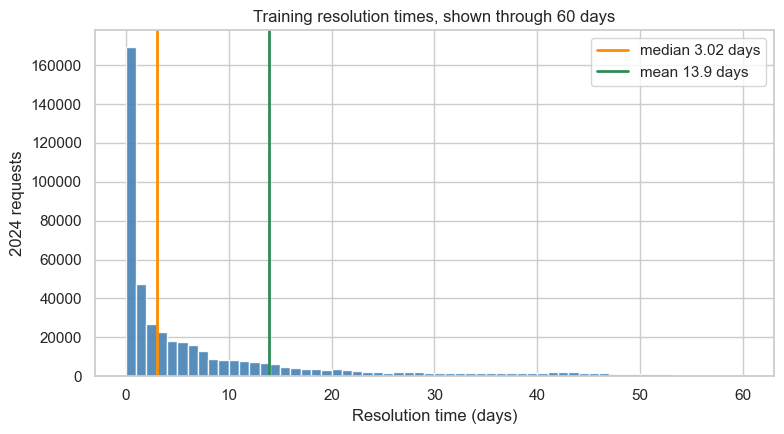

Share of 2024 requests beyond 60 days, omitted from the histogram: 4.6%


In [4]:
global_median = float(train["resolution_days"].median())
global_mean = float(train["resolution_days"].mean())

constant_scores = pd.DataFrame([
    {"rule": "2024 median for every request",
     **metrics(test["resolution_days"], test["log_resolution_days"], np.full(len(test), global_median))},
    {"rule": "2024 mean for every request",
     **metrics(test["resolution_days"], test["log_resolution_days"], np.full(len(test), global_mean))},
])
display(constant_scores.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(train["resolution_days"], bins=60, range=(0, 60), color="steelblue", alpha=0.9)
ax.axvline(global_median, color="darkorange", linewidth=2, label=f"median {global_median:.2f} days")
ax.axvline(global_mean, color="seagreen", linewidth=2, label=f"mean {global_mean:.1f} days")
ax.set_xlabel("Resolution time (days)")
ax.set_ylabel("2024 requests")
ax.set_title("Training resolution times, shown through 60 days")
ax.legend()
savefig("23_baseline_distribution")

share_past_60 = (train["resolution_days"] > 60).mean()
print(f"Share of 2024 requests beyond 60 days, omitted from the histogram: {share_past_60:.1%}")

On 2025 the median is the better typical guess: MAE 14.7 days, against 18.3 days for the mean. The mean wins RMSE, 36.9 against 38.9, and its day-scale R² is about zero. That is what a constant near the test-set mean does on a squared-error score. It is a poor description of a typical request, and on the log scale it scores R² −0.56, because 13.9 days sits far out in a distribution whose middle is 3 days.

The histogram makes the same point. The median falls in the tall part of the distribution. The mean falls out in the tail. The rest of this notebook uses the median.

## 4. One median for every request

Every 2025 request is predicted as the 2024 median, 3.02 days. The monthly medians below are the check on whether that single level is even in the right place.

2025 resolution time by month filed


,n,median_days,mean_days
Jan,43276,2.0600,12.2400
Feb,36270,2.8200,14.4500
Mar,39759,2.5100,14.5100
Apr,3085,2.9800,36.1200
May,11140,2.0500,17.0600
Jun,46829,2.9900,12.4300
Jul,49226,4.0800,13.8200
Aug,51860,3.5200,15.3500
Sep,44008,3.9700,18.7900
Oct,42162,3.1500,19.1100


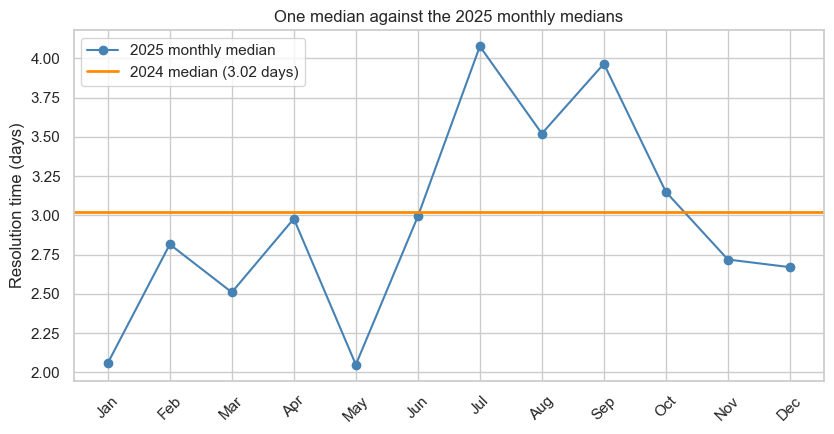

In [5]:
by_month = (
    test.groupby("created_month")["resolution_days"]
    .agg(n="size", median_days="median", mean_days="mean")
)
by_month.index = MONTH_NAMES
print("2025 resolution time by month filed")
display(by_month.round(2))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(range(1, 13), by_month["median_days"], marker="o", color="steelblue", label="2025 monthly median")
ax.axhline(global_median, color="darkorange", linewidth=2, label=f"2024 median ({global_median:.2f} days)")
ax.set_xticks(range(1, 13), MONTH_NAMES, rotation=45)
ax.set_ylabel("Resolution time (days)")
ax.set_title("One median against the 2025 monthly medians")
ax.legend()
savefig("24_baseline_by_month")

Monthly medians in 2025 run from about 2.0 days to about 4.1 days. The guess of 3.02 days sits inside that band. The baseline is not missing because 2025 is a different year.

April is a thin slice, about 3,000 requests against 30,000–50,000 in a full month, and its median is still about 3 days. Its mean is much higher. That is the long tail, which a median rule is built to ignore.

The miss is inside each month. A month mixes requests that close in hours with requests that close in weeks, and one number cannot be all of them.

## 5. One median per request type

Request type is known at filing. Types with fewer than 200 training requests share one "Other" median, as does any 2025 type that never reached that count in 2024. That is the same grouping the later notebooks use, and it leaves every test row with a prediction.

Type medians: 139 levels, from 0.0003 to 162.0 days
Share of 2024 requests in a type whose median is within 1 day of 3.02: 20.2%


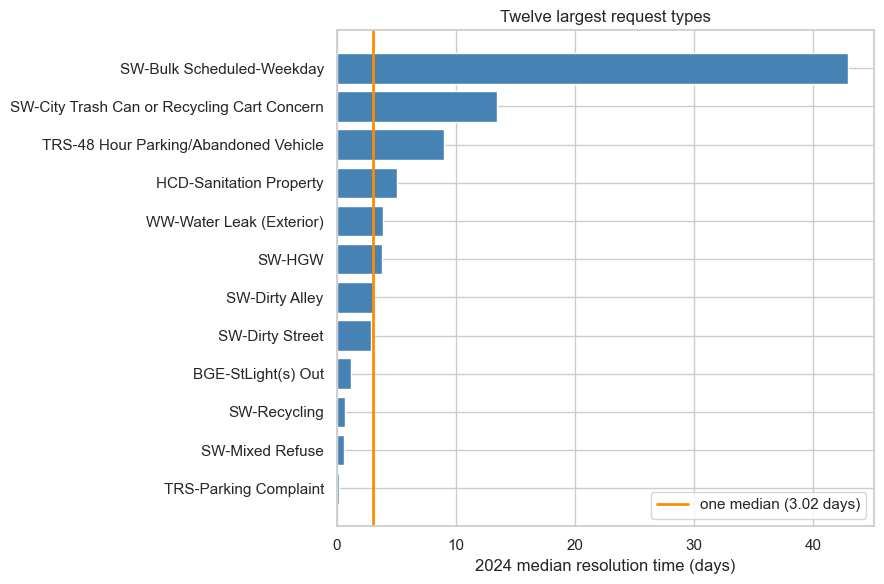

The twelve largest types, 2024 median against the 2025 median


,n_2024,median_2024,n_2025,median_2025
request_type,,,,
HCD-Sanitation Property,37778,5.0300,30957,5.1300
TRS-Parking Complaint,34523,0.1400,46179,0.4600
SW-HGW,24441,3.8200,20203,1.2300
TRS-48 Hour Parking/Abandoned Vehicle,23381,9.0000,9189,12.7700
SW-Dirty Alley,19610,3.0200,19250,5.2500
SW-Bulk Scheduled-Weekday,18300,42.9600,15671,47.0100
SW-City Trash Can or Recycling Cart Concern,16499,13.4200,14765,14.0800
SW-Mixed Refuse,15326,0.5700,18103,0.8000
SW-Dirty Street,14969,2.8700,12207,5.2400


In [6]:
type_median = train.groupby("request_type", observed=True)["resolution_days"].median()
pred_type = test["request_type"].map(type_median)
assert pred_type.notna().all()

near = train["request_type"].map(type_median).sub(global_median).abs().le(1)
print(f"Type medians: {len(type_median)} levels, from {type_median.min():.4f} to {type_median.max():.1f} days")
print(f"Share of 2024 requests in a type whose median is within 1 day of {global_median:.2f}: {near.mean():.1%}")

top = train["request_type"].value_counts().head(12).index
top_medians = type_median.loc[top].sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_medians.index, top_medians.values, color="steelblue")
ax.axvline(global_median, color="darkorange", linewidth=2, label=f"one median ({global_median:.2f} days)")
ax.set_xlabel("2024 median resolution time (days)")
ax.set_title("Twelve largest request types")
ax.legend()
savefig("25_type_medians")

type_2025 = test.groupby("request_type")["resolution_days"].median()
drift = pd.DataFrame({
    "n_2024": train["request_type"].value_counts(),
    "median_2024": type_median,
    "n_2025": test["request_type"].value_counts(),
    "median_2025": type_2025,
}).loc[top]
drift = drift.sort_values("n_2024", ascending=False)
drift["n_2024"] = drift["n_2024"].astype(int)
drift["n_2025"] = drift["n_2025"].astype(int)
print("The twelve largest types, 2024 median against the 2025 median")
display(drift.round({"median_2024": 2, "median_2025": 2}))

About one fifth of 2024 requests belong to a type whose own median is within a day of 3.02. The other four fifths are types a single number systematically misses.

Among the high-volume types the spread is the story. Parking complaints have a 2024 median of 0.14 days. Weekday bulk collection has a median of 43 days. Sanitation-property complaints, the most common type, sit near 5 days. The orange line on the chart is the single median, and most of these bars are not on it.

The 2024 medians mostly carry over to 2025. Bulk collection is 43 days, then 47. Parking complaints stay under a day. A few common types move: SW-HGW from 3.8 days to 1.2, dirty alley and dirty street from about 3 days to about 5.3, and 48-hour abandoned vehicles from 9.0 to 12.8. The rule transfers, with some drift.

## 6. What the second median changes

Both rules are scored on the same 2025 requests. `R2_log` converts the day prediction with log(1 + days). It is not a model fit on the log scale.

2025 test set


,model,features,MAE,RMSE,R2,R2_log
0,"Median, all requests",--,14.7120,38.8830,-0.1150,-0.0350
1,Median per request type,--,11.9150,35.9590,0.0470,0.2640


R² on the log scale, predicting each type's mean log time instead: 0.301


2025 MAE in days, twelve largest types


,n_2025,median_2024,mae_one_median,mae_type_median,mae_drop
request_type,,,,,
SW-Dirty Street,12207,2.8700,4.0200,4.0800,-0.0600
SW-HGW,20203,3.8200,8.0100,8.0700,-0.0600
WW-Water Leak (Exterior),11986,3.8500,22.4400,22.4600,-0.0100
SW-Dirty Alley,19250,3.0200,4.0200,4.0200,-0.0000
BGE-StLight(s) Out,8431,1.1600,14.1500,13.7200,0.4200
HCD-Sanitation Property,30957,5.0300,3.7700,3.3400,0.4300
TRS-Parking Complaint,46179,0.1400,26.1700,25.4600,0.7100
SW-Mixed Refuse,18103,0.5700,2.1300,0.8800,1.2500
SW-Recycling,17075,0.6700,2.1000,0.7900,1.3200


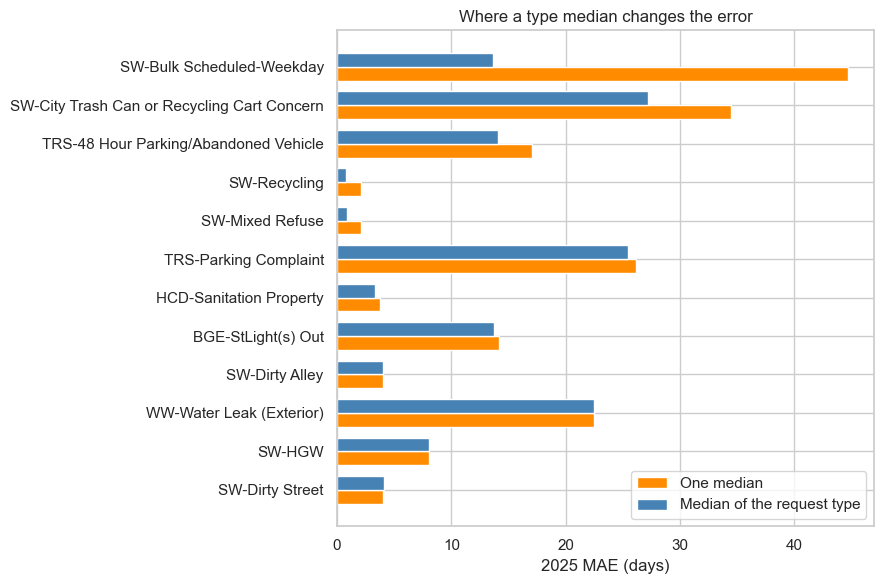

Wrote C:\Users\manik\OneDrive\Desktop\JHU\SEM 3\data mining\311\results\baseline_metrics.csv


In [7]:
pred_global = np.full(len(test), global_median)
scores = pd.DataFrame([
    {"model": "Median, all requests", "features": "--",
     **metrics(test["resolution_days"], test["log_resolution_days"], pred_global)},
    {"model": "Median per request type", "features": "--",
     **metrics(test["resolution_days"], test["log_resolution_days"], pred_type.to_numpy())},
])
print("2025 test set")
display(scores.round(3))

# The mean of log time within a type is a different rule. Recorded here so the
# log-scale number is not later confused with the median's log-scale number.
type_mean_log = train.groupby("request_type")["log_resolution_days"].mean()
log_pred = test["request_type"].map(type_mean_log).to_numpy()
log_true = test["log_resolution_days"].to_numpy()
r2_mean_log = 1 - ((log_true - log_pred) ** 2).sum() / ((log_true - log_true.mean()) ** 2).sum()
print(f"R² on the log scale, predicting each type's mean log time instead: {r2_mean_log:.3f}")

test = test.copy()
test["ae_global"] = (test["resolution_days"] - global_median).abs()
test["ae_type"] = (test["resolution_days"] - pred_type.to_numpy()).abs()
by_type = (
    test[test["request_type"].isin(top)]
    .groupby("request_type")
    .agg(n_2025=("resolution_days", "size"),
         median_2024=("request_type", lambda s: type_median.loc[s.iloc[0]]),
         mae_one_median=("ae_global", "mean"),
         mae_type_median=("ae_type", "mean"))
)
by_type["mae_drop"] = by_type["mae_one_median"] - by_type["mae_type_median"]
by_type = by_type.sort_values("mae_drop", ascending=True)
print("2025 MAE in days, twelve largest types")
display(by_type.round(2))

fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(by_type))
ax.barh(y - 0.18, by_type["mae_one_median"], height=0.36, color="darkorange", label="One median")
ax.barh(y + 0.18, by_type["mae_type_median"], height=0.36, color="steelblue", label="Median of the request type")
ax.set_yticks(y, by_type.index)
ax.set_xlabel("2025 MAE (days)")
ax.set_title("Where a type median changes the error")
ax.legend()
savefig("26_baseline_mae_by_type")

scores.to_csv(RESULTS_DIR / "baseline_metrics.csv", index=False)
print(f"Wrote {RESULTS_DIR / 'baseline_metrics.csv'}")

Moving from one median to a median per type lowers 2025 MAE from 14.7 days to 11.9 days. RMSE falls from 38.9 to 36.0. Day-scale R² goes from −0.11 to 0.05. Most of what a median rule can explain is the request type, and even that leaves R² near zero, because squared error is dominated by requests that take months.

The MAE drop is concentrated. Weekday bulk collection is the large one: predicting 3 days for a type whose median is 43 days costs about 45 days of MAE, and the type median brings that to about 14. Trash-cart concerns drop by about 7 days of MAE. Several common types barely move. Dirty-alley complaints have a 2024 median of 3.02 days, the same as the single median, so the second rule has nothing to change. Parking complaints stay near 25 days of MAE either way. Their median is 0.14 days, but a long tail of slow complaints keeps the average absolute error large. A median is the right typical guess for that type and still a weak MAE.

On the log scale the type-median row is 0.26. Predicting each type's mean log time instead scores 0.30. That second number is a different rule, and it is higher on a log-scale R² by construction. The comparison uses the median.

The bar for the linear regression, on this same 2025 test set, is an MAE below 11.9 days.